# Supplementary Fig. 1c: number of recording sites per layer of the Horvath probe and of the simulated dense probe

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel c of Supplementary Fig. 1 of the paper: the number of recording sites per cortical layer of the Horvath probe (in vivo setup, filled grey bars) against that of the simulated dense probe (empty red bars). Source data and svg are saved in figures/8_source_data/supp_fig1c/.

**method**
* both probes have 3 depths of 128 sites (384 sites). The layer of each site is a property (`layers`) of the recording extractor of the depth: `dataset/00_raw/recording_horvath_probe{1,2,3}` for the Horvath probe and `dataset/00_raw/recording_dense_probe{1,2,3}` for the simulated dense probe
* layers 2 and 3 are merged (L2/3) and the sites outside of the cortex are labelled "Out"
* the layers of the sites of the simulated probe were obtained from the circuit atlas when the probe was positioned (`notebooks/1_results/supp_fig1_B_method_depths.ipynb`); the counts here are read from the recordings

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
import subprocess
import tempfile
from PIL import Image
import re

# paths: recordings of the three depths of the Horvath probe (in vivo) and of the simulated dense probe
HORVATH_PATHS = ["dataset/00_raw/recording_horvath_probe1", "dataset/00_raw/recording_horvath_probe2", "dataset/00_raw/recording_horvath_probe3"]
DENSE_PATHS = ["dataset/00_raw/recording_dense_probe1", "dataset/00_raw/recording_dense_probe2", "dataset/00_raw/recording_dense_probe3"]

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 1.1
plt.rcParams["axes.linewidth"] = 1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}# paths
DATA_PATH = "dataset/01_intermediate/supplementary/lfp_validation/lfp_infinitesimal_vs_finite.csv"

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 1.1
plt.rcParams["axes.linewidth"] = 1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Number of recording sites per layer

In [2]:
%%time

LAYERS = ["L1", "L2/3", "L4", "L5", "L6", "Out"]
LAYER_NAMES = {"L1": "L1", "L2": "L2/3", "L3": "L2/3", "L2_3": "L2/3", "L4": "L4", "L5": "L5", "L6": "L6", "Outside": "Out"}

rows = []
for probe, paths in {"Horvath probe": HORVATH_PATHS, "Simulated dense probe": DENSE_PATHS}.items():
    for depth, path in enumerate(paths, start=1):
        layers = [LAYER_NAMES[l] for l in si.load_extractor(path).get_property("layers")]
        for layer in LAYERS:
            rows.append(dict(probe=probe, depth=depth, layer=layer, count=layers.count(layer)))
by_depth = pd.DataFrame(rows)
df = by_depth.groupby(["probe", "layer"], sort=False)["count"].sum().reset_index()
df["layer"] = pd.Categorical(df["layer"], LAYERS); df = df.sort_values(["probe", "layer"]).reset_index(drop=True)
display(df.pivot(index="layer", columns="probe", values="count").T)
print("sites per probe:", df.groupby("probe")["count"].sum().to_dict())

layer,L1,L2/3,L4,L5,L6,Out
probe,,,,,,
Horvath probe,36,68,20,88,80,92
Simulated dense probe,37,72,32,88,76,79


sites per probe: {'Horvath probe': 384, 'Simulated dense probe': 384}
CPU times: user 11.7 ms, sys: 0 ns, total: 11.7 ms
Wall time: 11.7 ms


## Plot, same as the paper's panel c

In [3]:
def plot_source_data(df: pd.DataFrame):
    """Number of recording sites per layer of the Horvath probe (filled grey bars) and of the simulated dense probe (empty red bars)"""

    layers = list(dict.fromkeys(df["layer"]))
    fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.05))
    horvath = df[df["probe"] == "Horvath probe"].set_index("layer").loc[layers, "count"]
    dense = df[df["probe"] == "Simulated dense probe"].set_index("layer").loc[layers, "count"]
    x = np.arange(1, len(layers) + 1)
    ax.bar(x=x, height=horvath.values, label="Horvath probe", width=0.7, facecolor=(0.7, 0.7, 0.7))
    ax.bar(x=x, height=dense.values, label="Simulated dense probe", width=0.7, facecolor="None", edgecolor="r")

    # legend
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 1.38), handletextpad=0.1, labelspacing=0.1)
    ax.set_ylabel("Recording sites\n(count)")
    ax.set_xlabel("Cortical layers")
    ax.spines[["top", "right"]].set_visible(False)

    # disconnect axes (R style)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.yaxis.set_ticks_position("left")
    ax.spines["left"].set_position(("axes", -0.05))
    ax.set_xticks(np.arange(0, len(layers) + 2, 1), [""] + layers + [""])
    ax.set_xlim([0, len(layers) + 1]); ax.set_ylim(0, 100); ax.set_yticks([0, 20, 40, 60, 80])
    fig.text(0.55, 1.62, "Distribution of electrode sites\nacross layers", ha="center", va="bottom", fontweight="bold", fontsize=6.5)
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 84.1 ms, sys: 8.02 ms, total: 92.2 ms
Wall time: 92.2 ms


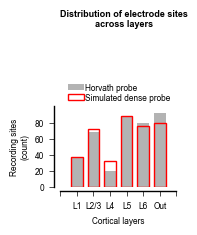

In [4]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/supp_fig1c", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig1c/supp_fig1c.svg", bbox_inches="tight", **savefig_cfg)

# save source data (sheet 1: counts per layer; sheet 2: counts per layer and depth of the probe)
with pd.ExcelWriter("figures/8_source_data/supp_fig1c/supp_fig1c.xlsx") as writer:
    df.to_excel(writer, sheet_name="sites_per_layer", index=False)
    by_depth.to_excel(writer, sheet_name="sites_per_layer_and_depth", index=False)

## Check: replot from the saved source data

CPU times: user 47.2 ms, sys: 29 µs, total: 47.2 ms
Wall time: 47.2 ms


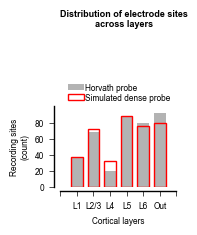

In [5]:
%%time

df = pd.read_excel("figures/8_source_data/supp_fig1c/supp_fig1c.xlsx", sheet_name="sites_per_layer")
fig, ax = plot_source_data(df)